# ARIMA & Statistical Forecasting for EnergyTrends

## Objective
This notebook trains and evaluates statistical forecasting models for the three core national energy series used in the LUMI **EnergyTrends** charts:

1. **Total Electricity Consumption** (`total_consumption_gwh`)
2. **Peak Electricity Demand** (`total_peak_demand_mw`)
3. **Clean Energy Generation** (`renewable_generation_gwh`)

The deployed model for each series is **ARIMA(1,1,1)**, refit on all available annual observations (**2003-2025**), producing forecasts for **2026-2030** with 95% confidence intervals.

## Why Statistical Models?
Only **23 annual observations** are available. With so few data points, advanced machine learning models (LSTM, Random Forest, XGBoost) overfit. Classical statistical models are parsimonious, interpretable, and appropriate for the thesis scope.

## Two phases — do not conflate
- **Evaluation** (unchanged protocol, reported in the thesis): models are trained on **2003-2020** and tested on the held-out **2021-2024** years using MAE / RMSE / MAPE. These are the numbers quoted in the thesis and defense deck.
- **Deployment** (this notebook's output): the selected ARIMA(1,1,1) is **refit on the full series 2003-2025** and forecasts **2026-2030**. Standard practice: validate on a holdout, then refit on all data before forecasting.

## Models compared in evaluation
- **Naive with Drift** — baseline/accuracy floor.
- **Linear Trend Regression** — straight-line trend, highly interpretable.
- **ARIMA(1,1,1)** — deployed model; handles autocorrelation and differencing.
- **Holt Linear Smoothing** — trend-aware exponential smoothing.

## Bonus validation
A **one-step-ahead check** is included per series: a model trained on 2003-2024 predicts 2025, which is compared against the actual 2025 observation — an additional pseudo-out-of-sample datapoint on the most recent year.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import Holt
from sklearn.linear_model import LinearRegression

%matplotlib inline

# Locate the master preprocessed data
candidates = [
    Path('master_preprocessed.csv'),
    Path('data_v2_preprocessed/master_preprocessed.csv'),
    Path('../data_v2_preprocessed/master_preprocessed.csv'),
    Path('../../data_v2_preprocessed/master_preprocessed.csv'),
    Path('DOE_Data_Extracted/data_v2_preprocessed/master_preprocessed.csv'),
]

data_file = None
for c in candidates:
    if c.exists():
        data_file = c.resolve()
        break

if data_file is None:
    raise FileNotFoundError('master_preprocessed.csv not found. Please run DOE_Data_Extracted/data_v2_preprocessing.py or copy the CSV next to this notebook.')

BASE_DIR = data_file.parent
V1_DIR = BASE_DIR.parent / 'data_v1'
print(f'Data: {data_file}')
print(f'Outputs will be written to: {BASE_DIR} (and {V1_DIR})')


Data: C:\Users\Admin\Documents\GitHub\Lumi\data\DOE_Data_Extracted\notebooks\master_preprocessed.csv
Outputs will be written to: C:\Users\Admin\Documents\GitHub\Lumi\data\DOE_Data_Extracted\notebooks (and C:\Users\Admin\Documents\GitHub\Lumi\data\DOE_Data_Extracted\data_v1)


## Helper Functions

- `evaluate_series` — trains the four candidate models on **2003-2020** and scores them on the held-out **2021-2024** years (the thesis's evaluation protocol; unchanged).
- `fit_deploy` — refits **ARIMA(1,1,1)** on the **entire** series and produces the deployed **2026-2030** forecast with 95% confidence intervals.
- `one_step_check` — fits on data through the second-to-last year and predicts the last year, reporting the percentage error.
- `plot_forecast` — renders history + forecast for visual inspection.


In [2]:
def evaluate_series(df, target_col):
    '''Thesis evaluation protocol: train <=2020, test 2021-2024. Returns a model-comparison table.'''
    train = df[df['year'] <= 2020][target_col].dropna()
    test = df[(df['year'] >= 2021) & (df['year'] <= 2024)][target_col].dropna()

    if len(train) < 3 or len(test) < 1:
        raise ValueError(f'Insufficient data for {target_col}')

    results = []

    # 1. Linear Trend Regression
    X_train = np.arange(len(train)).reshape(-1, 1)
    X_test = np.arange(len(train), len(train) + len(test)).reshape(-1, 1)
    lr = LinearRegression().fit(X_train, train.values)
    pred_lr = lr.predict(X_test)
    results.append({'model': 'Linear Trend Regression',
                    'mae': np.mean(np.abs(test.values - pred_lr)),
                    'rmse': np.sqrt(np.mean((test.values - pred_lr) ** 2)),
                    'mape': np.mean(np.abs((test.values - pred_lr) / test.values)) * 100})

    # 2. Holt Linear Smoothing
    holt = Holt(train.values, exponential=False, damped_trend=False, initialization_method='estimated').fit()
    pred_holt = holt.forecast(len(test))
    results.append({'model': 'Holt Linear Smoothing',
                    'mae': np.mean(np.abs(test.values - pred_holt)),
                    'rmse': np.sqrt(np.mean((test.values - pred_holt) ** 2)),
                    'mape': np.mean(np.abs((test.values - pred_holt) / test.values)) * 100})

    # 3. Naive with Drift
    drift = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
    pred_naive = [train.iloc[-1] + drift * (i + 1) for i in range(len(test))]
    pred_naive = np.array(pred_naive)
    results.append({'model': 'Naive with Drift',
                    'mae': np.mean(np.abs(test.values - pred_naive)),
                    'rmse': np.sqrt(np.mean((test.values - pred_naive) ** 2)),
                    'mape': np.mean(np.abs((test.values - pred_naive) / test.values)) * 100})

    # 4. ARIMA(1,1,1)
    arima = ARIMA(train, order=(1, 1, 1)).fit()
    pred_arima = arima.get_forecast(len(test)).predicted_mean.values
    results.append({'model': 'ARIMA(1,1,1)',
                    'mae': np.mean(np.abs(test.values - pred_arima)),
                    'rmse': np.sqrt(np.mean((test.values - pred_arima) ** 2)),
                    'mape': np.mean(np.abs((test.values - pred_arima) / test.values)) * 100})

    return pd.DataFrame(results)


def fit_deploy(df, target_col):
    '''Deployment fit: ARIMA(1,1,1) on the FULL series -> forecast the 5 years after the last actual.'''
    s = df.set_index('year')[target_col].dropna()
    last_year = int(s.index.max())
    model = ARIMA(s, order=(1, 1, 1)).fit()
    fcast = model.get_forecast(steps=5)
    ci = fcast.conf_int()
    forecast_df = pd.DataFrame({
        'year': list(range(last_year + 1, last_year + 6)),
        target_col: fcast.predicted_mean.values,
        'ci_lower': ci.iloc[:, 0].values,
        'ci_upper': ci.iloc[:, 1].values,
    })
    return forecast_df, model


def one_step_check(df, target_col):
    '''Fit on all years except the last; predict the last year; return predicted/actual/% error.'''
    s = df.set_index('year')[target_col].dropna()
    last_year = int(s.index.max())
    model = ARIMA(s.loc[:last_year - 1], order=(1, 1, 1)).fit()
    predicted = float(model.get_forecast(1).predicted_mean.iloc[0])
    actual = float(s.loc[last_year])
    return predicted, actual, abs(actual - predicted) / actual * 100


def plot_forecast(df, target_col, forecast_df, title, ylabel):
    hist = df[['year', target_col]].dropna()
    plt.figure(figsize=(10, 4))
    plt.plot(hist['year'], hist[target_col], marker='o', label='Historical')
    plt.plot(forecast_df['year'], forecast_df[target_col], marker='o', linestyle='--', color='red', label='ARIMA(1,1,1) forecast')
    plt.fill_between(forecast_df['year'], forecast_df['ci_lower'], forecast_df['ci_upper'], color='red', alpha=0.15, label='95% CI')
    plt.title(title)
    plt.xlabel('Year')
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


## Total Electricity Consumption — ARIMA(1,1,1)

Target: `total_consumption_gwh` (GWh).


C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


=== Model Comparison (Total Electricity Consumption, held-out 2021-2024) ===
                  model         mae        rmse     mape
Linear Trend Regression 5993.830753 7342.095036 4.965126
  Holt Linear Smoothing 6557.716104 7997.679152 5.435109
       Naive with Drift 6709.323529 8128.453097 5.566170
           ARIMA(1,1,1) 6829.090287 8257.124448 5.667112

One-step check: predicted 130,428 vs actual 126,378 -> 3.20% error

=== Deployed forecast (refit on full series) ===
 year  total_consumption_gwh      ci_lower      ci_upper
 2026          129677.785071 123659.400482 135696.169661
 2027          132977.558448 124354.183902 141600.932993
 2028          136277.320130 125580.361580 146974.278680
 2029          139577.070118 127070.752922 152083.387313
 2030          142876.808411 128723.655157 157029.961666


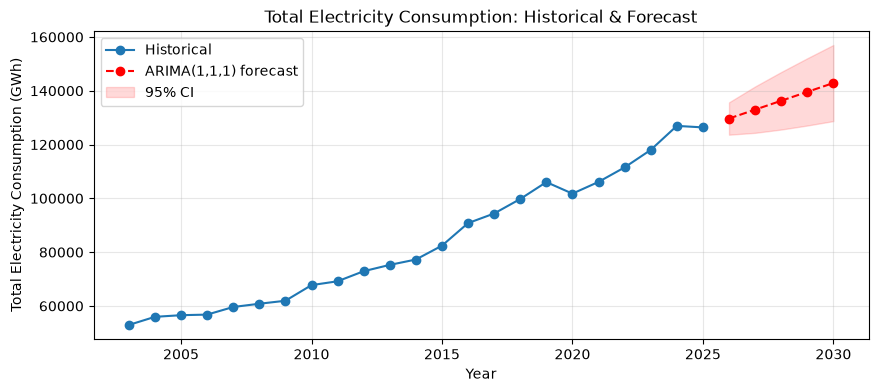

Saved forecast_consumption_2026_2030.csv (v2 + v1) and evaluation_consumption_2021_2024.csv


In [3]:
master = pd.read_csv(data_file).sort_values('year')

target = 'total_consumption_gwh'
comp = evaluate_series(master, target)
fc, model = fit_deploy(master, target)
pred, actual, err = one_step_check(master, target)

print('=== Model Comparison (Total Electricity Consumption, held-out 2021-2024) ===')
print(comp.to_string(index=False))
print(f'\nOne-step check: predicted {pred:,.0f} vs actual {actual:,.0f} -> {err:.2f}% error')
print('\n=== Deployed forecast (refit on full series) ===')
print(fc.to_string(index=False))

plot_forecast(master, target, fc, 'Total Electricity Consumption: Historical & Forecast', 'Total Electricity Consumption (GWh)')

fc.to_csv(BASE_DIR / 'forecast_consumption_2026_2030.csv', index=False)
comp.to_csv(BASE_DIR / 'evaluation_consumption_2021_2024.csv', index=False)
fc.to_csv(V1_DIR / 'forecast_consumption_2026_2030.csv', index=False)
print('Saved forecast_consumption_2026_2030.csv (v2 + v1) and evaluation_consumption_2021_2024.csv')


## Peak Electricity Demand — ARIMA(1,1,1)

Target: `total_peak_demand_mw` (MW).

*Note: on this series the AR coefficient estimate tends toward the boundary (≈1.0), so statsmodels may emit a `ConvergenceWarning` while returning the constrained optimum. The resulting forecast is a conservative trend extrapolation — documented in the defense notes.*


C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.st

=== Model Comparison (Peak Electricity Demand, held-out 2021-2024) ===
                  model         mae        rmse     mape
Linear Trend Regression 1180.049622 1402.876408 6.561632
  Holt Linear Smoothing  996.805111 1275.509151 5.481917
       Naive with Drift  996.808824 1275.512970 5.481938
           ARIMA(1,1,1) 1019.847089 1299.266697 5.611756

One-step check: predicted 19,788 vs actual 19,212 -> 3.00% error

=== Deployed forecast (refit on full series) ===
 year  total_peak_demand_mw     ci_lower     ci_upper
 2026          19699.225382 18743.878385 20654.572379
 2027          20186.445660 18810.199017 21562.692303
 2028          20673.660835 18957.820107 22389.501563
 2029          21160.870906 19145.217110 23176.524701
 2030          21648.075873 19356.719097 23939.432649


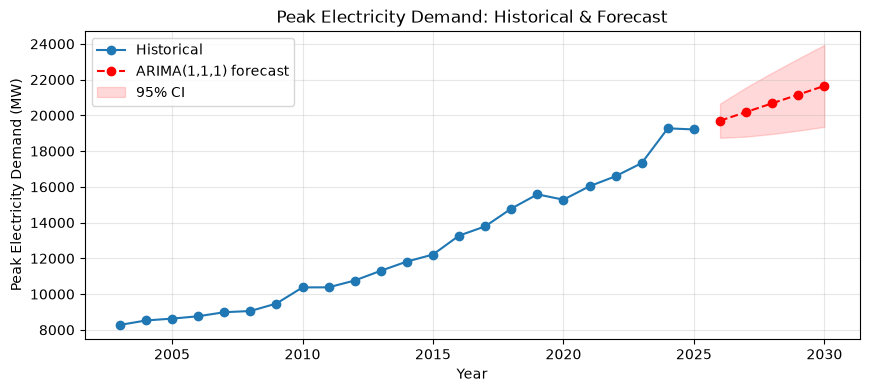

Saved forecast_peak_demand_2026_2030.csv (v2 + v1) and evaluation_peak_demand_2021_2024.csv


In [4]:
target = 'total_peak_demand_mw'
comp = evaluate_series(master, target)
fc, model = fit_deploy(master, target)
pred, actual, err = one_step_check(master, target)

print('=== Model Comparison (Peak Electricity Demand, held-out 2021-2024) ===')
print(comp.to_string(index=False))
print(f'\nOne-step check: predicted {pred:,.0f} vs actual {actual:,.0f} -> {err:.2f}% error')
print('\n=== Deployed forecast (refit on full series) ===')
print(fc.to_string(index=False))

plot_forecast(master, target, fc, 'Peak Electricity Demand: Historical & Forecast', 'Peak Electricity Demand (MW)')

fc.to_csv(BASE_DIR / 'forecast_peak_demand_2026_2030.csv', index=False)
comp.to_csv(BASE_DIR / 'evaluation_peak_demand_2021_2024.csv', index=False)
fc.to_csv(V1_DIR / 'forecast_peak_demand_2026_2030.csv', index=False)
print('Saved forecast_peak_demand_2026_2030.csv (v2 + v1) and evaluation_peak_demand_2021_2024.csv')


## Clean Energy Generation — ARIMA(1,1,1)

Target: `renewable_generation_gwh` (GWh).


=== Model Comparison (Clean Energy Generation, held-out 2021-2024) ===
                  model         mae        rmse      mape
Linear Trend Regression 2504.098641 2926.936152  9.404520
  Holt Linear Smoothing 2504.107778 2926.944681  9.404556
       Naive with Drift 3450.220588 3778.581304 13.106343
           ARIMA(1,1,1) 3597.368653 3939.666989 13.665238

One-step check: predicted 28,088 vs actual 31,647 -> 11.25% error

=== Deployed forecast (refit on full series) ===
 year  renewable_generation_gwh     ci_lower     ci_upper
 2026              32505.843588 29837.425115 35174.262061
 2027              31996.427333 27683.469360 36309.385305
 2028              32298.583540 27066.835315 37530.331765
 2029              32119.361985 25978.912529 38259.811441
 2030              32225.665827 25363.035820 39088.295835


C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  s

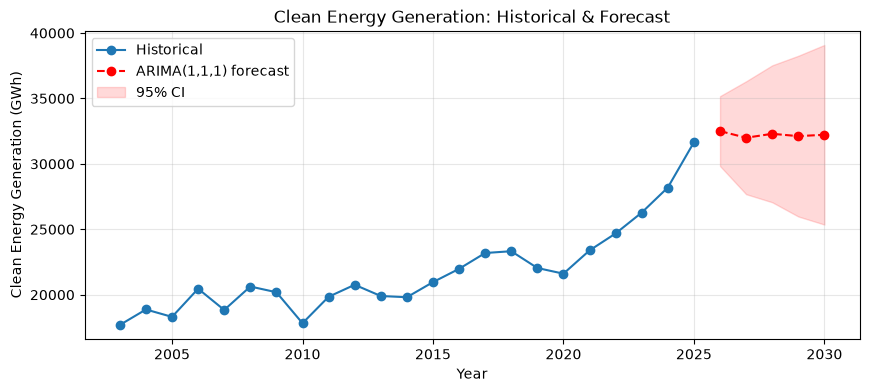

Saved forecast_renewable_generation_2026_2030.csv (v2 + v1) and evaluation_renewable_generation_2021_2024.csv


In [5]:
target = 'renewable_generation_gwh'
comp = evaluate_series(master, target)
fc, model = fit_deploy(master, target)
pred, actual, err = one_step_check(master, target)

print('=== Model Comparison (Clean Energy Generation, held-out 2021-2024) ===')
print(comp.to_string(index=False))
print(f'\nOne-step check: predicted {pred:,.0f} vs actual {actual:,.0f} -> {err:.2f}% error')
print('\n=== Deployed forecast (refit on full series) ===')
print(fc.to_string(index=False))

plot_forecast(master, target, fc, 'Clean Energy Generation: Historical & Forecast', 'Clean Energy Generation (GWh)')

fc.to_csv(BASE_DIR / 'forecast_renewable_generation_2026_2030.csv', index=False)
comp.to_csv(BASE_DIR / 'evaluation_renewable_generation_2021_2024.csv', index=False)
fc.to_csv(V1_DIR / 'forecast_renewable_generation_2026_2030.csv', index=False)
print('Saved forecast_renewable_generation_2026_2030.csv (v2 + v1) and evaluation_renewable_generation_2021_2024.csv')


## Summary

For each EnergyTrends series this notebook (a) reproduces the thesis's evaluation table on the held-out 2021-2024 years, (b) reports a one-step check against the most recent actual, and (c) produces the **deployed** ARIMA(1,1,1) forecast for **2026-2030** with 95% confidence intervals, refit on all observations through 2025.

### Files generated

| File | Description |
|---|---|
| `forecast_consumption_2026_2030.csv` | 5-year consumption forecast with CI (v2 + v1) |
| `forecast_peak_demand_2026_2030.csv` | 5-year peak demand forecast with CI (v2 + v1) |
| `forecast_renewable_generation_2026_2030.csv` | 5-year renewable generation forecast with CI (v2 + v1) |
| `evaluation_consumption_2021_2024.csv` | Held-out comparison, consumption |
| `evaluation_peak_demand_2021_2024.csv` | Held-out comparison, peak demand |
| `evaluation_renewable_generation_2021_2024.csv` | Held-out comparison, renewable generation |

The `forecast_*_2026_2030.csv` files are loaded by `fastapi-backend/app/ml/predictor.py` and used in the LUMI dashboard; the `evaluation_*` files are provenance for the held-out comparison only.

**Note on model-comparison numbers:** this notebook's comparison is illustrative — the canonical evaluation artifacts quoted in the thesis live in `docs/09-Technical-Evaluation/artifacts/rerun-2026-09-15/ml/` (six models including SARIMAX+Exog and Random Forest). The `/model-comparison` API serves those canonical numbers.

**Superseded artifacts:** the earlier `forecast_*_2025_2030.csv` files were generated under the evaluation configuration (trained on <=2020) and are superseded by this refit; they are retained for provenance only.


In [6]:
# Verify all expected CSVs are present
expected = [
    'master_preprocessed.csv',
    'forecast_consumption_2026_2030.csv',
    'forecast_peak_demand_2026_2030.csv',
    'forecast_renewable_generation_2026_2030.csv',
    'evaluation_consumption_2021_2024.csv',
    'evaluation_peak_demand_2021_2024.csv',
    'evaluation_renewable_generation_2021_2024.csv',
]
for f in expected:
    path = BASE_DIR / f
    status = '\u2705' if path.exists() else '\u274c'
    print(f'{status} {f}')


✅ master_preprocessed.csv
✅ forecast_consumption_2026_2030.csv
✅ forecast_peak_demand_2026_2030.csv
✅ forecast_renewable_generation_2026_2030.csv
✅ evaluation_consumption_2021_2024.csv
✅ evaluation_peak_demand_2021_2024.csv
✅ evaluation_renewable_generation_2021_2024.csv
